# 01 — Data exploration

Saved outputs are historical results from the supplied notebooks. Edited cells have cleared outputs. Run in order from a fresh kernel to reproduce; **Run All in notebooks 02 and 03 retrains models**. Keep your existing models and predictions.


In [2]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Python location: c:\Users\mahim\AppData\Local\Programs\Python\Python313\python.exe


In [3]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Current working folder:", Path.cwd())

Libraries imported successfully!
Current working folder: d:\DigiCrome Academy\Internship\Nexthikes\P6\Notebooks\01_data_exploration.ipynb


In [5]:
# Locate the data folder
current_folder = Path.cwd()

data_dir = next(
    (
        folder / "data"
        for folder in [current_folder, *current_folder.parents]
        if (folder / "data" / "train.csv").is_file()
    ),
    None
)

if data_dir is None:
    raise FileNotFoundError(
        "Cannot find data/train.csv. Check that the CSV files are in your data folder."
    )

print("Data folder:", data_dir)

# Read the CSV files
train = pd.read_csv(
    data_dir / "train.csv",
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"}
)

test = pd.read_csv(
    data_dir / "test.csv",
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"}
)

store = pd.read_csv(data_dir / "store.csv")
sample_submission = pd.read_csv(data_dir / "sample_submission.csv")

# Check the size of each dataset
for name, df in {
    "Train": train,
    "Test": test,
    "Store": store,
    "Sample submission": sample_submission
}.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

display(train.head())

Data folder: d:\DigiCrome Academy\Internship\Nexthikes\P6\data
Train: 1,017,209 rows, 9 columns
Test: 41,088 rows, 8 columns
Store: 1,115 rows, 10 columns
Sample submission: 41,088 rows, 2 columns


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [6]:
datasets = {
    "Train": train,
    "Test": test,
    "Store": store,
    "Sample submission": sample_submission
}

for name, df in datasets.items():
    print(f"\n{name} dataset")
    print(f"Duplicate rows: {df.duplicated().sum():,}")

    summary = pd.DataFrame({
        "Data type": df.dtypes.astype(str),
        "Missing values": df.isna().sum(),
        "Missing (%)": (df.isna().mean() * 100).round(2)
    })

    display(summary)

# Check whether identifiers are repeated
print("\nDuplicate identifiers:")
print("Train Store-Date pairs:", train.duplicated(["Store", "Date"]).sum())
print("Test Store-Date pairs:", test.duplicated(["Store", "Date"]).sum())
print("Store IDs:", store.duplicated(["Store"]).sum())
print("Test IDs:", test.duplicated(["Id"]).sum())


Train dataset
Duplicate rows: 0


,Data type,Missing values,Missing (%)
Store,int64,0,0.0
DayOfWeek,int64,0,0.0
Date,datetime64[us],0,0.0
Sales,int64,0,0.0
Customers,int64,0,0.0
Open,int64,0,0.0
Promo,int64,0,0.0
StateHoliday,string,0,0.0
SchoolHoliday,int64,0,0.0



Test dataset
Duplicate rows: 0


,Data type,Missing values,Missing (%)
Id,int64,0,0.00
Store,int64,0,0.00
DayOfWeek,int64,0,0.00
Date,datetime64[us],0,0.00
Open,float64,11,0.03
Promo,int64,0,0.00
StateHoliday,string,0,0.00
SchoolHoliday,int64,0,0.00



Store dataset
Duplicate rows: 0


,Data type,Missing values,Missing (%)
Store,int64,0,0.00
StoreType,str,0,0.00
Assortment,str,0,0.00
CompetitionDistance,float64,3,0.27
CompetitionOpenSinceMonth,float64,354,31.75
CompetitionOpenSinceYear,float64,354,31.75
Promo2,int64,0,0.00
Promo2SinceWeek,float64,544,48.79
Promo2SinceYear,float64,544,48.79
PromoInterval,str,544,48.79



Sample submission dataset
Duplicate rows: 0


,Data type,Missing values,Missing (%)
Id,int64,0,0.0
Sales,int64,0,0.0



Duplicate identifiers:
Train Store-Date pairs: 0
Test Store-Date pairs: 0
Store IDs: 0
Test IDs: 0


In [7]:
# 1. Check missing promotion details by participation
promo_columns = [
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "PromoInterval"
]

print("Number of stores in each Promo2 group:")
display(
    store.groupby("Promo2")
    .size()
    .rename("Number of stores")
    .to_frame()
)

print("Missing promotion details in each group:")
display(
    store.groupby("Promo2")[promo_columns]
    .agg(lambda column: column.isna().sum())
)

# 2. Inspect the test rows with unknown opening status
missing_open = test.loc[test["Open"].isna()].copy()

print("Test rows with missing Open:")
display(missing_open)

# 3. Inspect historical opening patterns for these stores
affected_stores = missing_open["Store"].unique()

opening_history = (
    train.loc[train["Store"].isin(affected_stores)]
    .groupby(["Store", "DayOfWeek"])["Open"]
    .agg(Recorded_days="size", Open_rate="mean")
    .reset_index()
)

print("Historical opening patterns:")
display(opening_history)

Number of stores in each Promo2 group:


,Number of stores
Promo2,
0,544
1,571


Missing promotion details in each group:


,Promo2SinceWeek,Promo2SinceYear,PromoInterval
Promo2,,,
0,544,544,544
1,0,0,0


Test rows with missing Open:


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0


Historical opening patterns:


,Store,DayOfWeek,Recorded_days,Open_rate
0,622,1,134,0.955224
1,622,2,135,0.992593
2,622,3,135,0.977778
3,622,4,135,0.940741
4,622,5,135,0.955556
5,622,6,134,1.000000
6,622,7,134,0.000000


In [8]:
# Preserve the original datasets
train_clean = train.copy()
test_clean = test.copy()
store_clean = store.copy()

# Flag and fill the 11 unknown opening statuses
test_clean["OpenWasMissing"] = test_clean["Open"].isna().astype(int)
test_clean["Open"] = test_clean["Open"].fillna(1).astype(int)

# Matching column in the training data
train_clean["OpenWasMissing"] = train_clean["Open"].isna().astype(int)

# Label promotion intervals that do not apply
no_promo2 = store_clean["Promo2"].eq(0)

store_clean.loc[no_promo2, "PromoInterval"] = "NotParticipating"

# Leave missing promotion dates as missing:
# a non-participating store has no promotion start date.

# Flag unknown competitor information
store_clean["CompetitionDistanceMissing"] = (
    store_clean["CompetitionDistance"].isna().astype(int)
)

store_clean["CompetitionStartMissing"] = (
    store_clean[
        ["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]
    ].isna().any(axis=1).astype(int)
)

print("Open values imputed:", test_clean["OpenWasMissing"].sum())
print("Remaining missing Open values:", test_clean["Open"].isna().sum())

print("\nPromotion intervals:")
display(store_clean["PromoInterval"].value_counts(dropna=False))

print("\nMissing competitor information:")
display(
    store_clean[
        ["CompetitionDistanceMissing", "CompetitionStartMissing"]
    ].sum().rename("Number of stores").to_frame()
)

Open values imputed: 11
Remaining missing Open values: 0

Promotion intervals:


PromoInterval
NotParticipating    544
Jan,Apr,Jul,Oct     335
Feb,May,Aug,Nov     130
Mar,Jun,Sept,Dec    106
Name: count, dtype: int64


Missing competitor information:


,Number of stores
CompetitionDistanceMissing,3
CompetitionStartMissing,354


In [9]:
# Add store details to training records
train_merged = train_clean.merge(
    store_clean,
    on="Store",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Add store details to test records
test_merged = test_clean.merge(
    store_clean,
    on="Store",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verify every record matched a store
for name, merged, original in [
    ("Train", train_merged, train_clean),
    ("Test", test_merged, test_clean)
]:
    unmatched = merged["_merge"].eq("left_only").sum()

    print(f"{name}: {len(merged):,} rows")
    print(f"Unmatched store records: {unmatched}")

    assert len(merged) == len(original), "Row count changed!"
    assert unmatched == 0, "Some stores have no matching details!"

# Remove the temporary matching-status column
train_merged = train_merged.drop(columns="_merge")
test_merged = test_merged.drop(columns="_merge")

print("\nFinal shapes:")
print("Train:", train_merged.shape)
print("Test:", test_merged.shape)

display(
    train_merged[
        ["Store", "Date", "Sales", "StoreType",
         "Assortment", "CompetitionDistance", "Promo2"]
    ].head()
)

Train: 1,017,209 rows
Unmatched store records: 0
Test: 41,088 rows
Unmatched store records: 0

Final shapes:
Train: (1017209, 21)
Test: (41088, 20)


,Store,Date,Sales,StoreType,Assortment,CompetitionDistance,Promo2
0,1,2015-07-31,5263,c,a,1270.0,0
1,2,2015-07-31,6064,a,a,570.0,1
2,3,2015-07-31,8314,a,a,14130.0,1
3,4,2015-07-31,13995,c,c,620.0,0
4,5,2015-07-31,4822,a,a,29910.0,0


In [10]:
import logging

# Locate the project's logs folder
project_dir = data_dir.parent
log_dir = project_dir / "logs"
log_dir.mkdir(parents=True, exist_ok=True)

# Create a logger for this project
logger = logging.getLogger("rossmann")
logger.setLevel(logging.INFO)
logger.propagate = False

# Avoid duplicate messages if you rerun this cell
for handler in logger.handlers[:]:
    handler.close()
    logger.removeHandler(handler)

file_handler = logging.FileHandler(
    log_dir / "project.log",
    mode="a",
    encoding="utf-8"
)

file_handler.setFormatter(
    logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
)

logger.addHandler(file_handler)

# Record a summary of the work already completed
logger.info("Logging started. Summary of preparation completed so far:")
logger.info("Loaded train=%s and test=%s", train.shape, test.shape)
logger.info(
    "Imputed %d missing test Open values as 1 based on historical "
    "opening patterns; these values remain assumptions.",
    test_clean["OpenWasMissing"].sum()
)
logger.info("Labelled non-participating Promo2 stores.")
logger.info("Retained and flagged unknown competitor information.")
logger.info(
    "Merged store details: train=%s, test=%s; all records matched.",
    train_merged.shape,
    test_merged.shape
)

print("Log file created:", log_dir / "project.log")

Log file created: d:\DigiCrome Academy\Internship\Nexthikes\P6\logs\project.log


In [11]:
# Summary of sales and customer numbers
display(
    train_merged[["Sales", "Customers"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
    .round(2)
)

# Check potentially unusual records
checks = pd.Series({
    "Negative sales": (train_merged["Sales"] < 0).sum(),
    "Negative customers": (train_merged["Customers"] < 0).sum(),
    "Closed but positive sales": (
        (train_merged["Open"] == 0) &
        (train_merged["Sales"] > 0)
    ).sum(),
    "Open but zero sales": (
        (train_merged["Open"] == 1) &
        (train_merged["Sales"] == 0)
    ).sum(),
    "Positive sales but zero customers": (
        (train_merged["Sales"] > 0) &
        (train_merged["Customers"] == 0)
    ).sum()
}, name="Number of records")

display(checks.to_frame())

# Compare zero and positive sales for open and closed stores
sales_status = pd.crosstab(
    train_merged["Open"].map({0: "Closed", 1: "Open"}),
    train_merged["Sales"].eq(0).map({
        True: "Zero sales",
        False: "Nonzero sales"
    })
)

display(sales_status)

logger.info("Completed sales/customer summary and consistency checks.")
logger.info("Check results: %s", checks.to_dict())

,Sales,Customers
count,1017209.00,1017209.00
mean,5773.82,633.15
std,3849.93,464.41
min,0.00,0.00
25%,3727.00,405.00
50%,5744.00,609.00
75%,7856.00,837.00
95%,12137.00,1362.00
99%,17160.00,2267.00
max,41551.00,7388.00


,Number of records
Negative sales,0
Negative customers,0
Closed but positive sales,0
Open but zero sales,54
Positive sales but zero customers,0


Sales,Nonzero sales,Zero sales
Open,,
Closed,0,172817
Open,844338,54


In [12]:
# Find open-store records with zero sales
open_zero_sales = train_merged.loc[
    train_merged["Open"].eq(1) &
    train_merged["Sales"].eq(0)
].copy()

print("Open-store records with zero sales:", len(open_zero_sales))
print("Affected stores:", open_zero_sales["Store"].nunique())

print("\nCustomer counts in these records:")
display(
    open_zero_sales["Customers"]
    .value_counts()
    .rename_axis("Customers")
    .to_frame("Number of records")
)

print("\nFirst 15 records:")
display(
    open_zero_sales[
        ["Store", "Date", "DayOfWeek", "Sales",
         "Customers", "Promo", "StateHoliday"]
    ].sort_values(["Store", "Date"]).head(15)
)

print("\nStores with the most zero-sales open days:")
display(
    open_zero_sales.groupby("Store")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Zero-sales open days")
)

logger.info(
    "Inspected %d zero-sales open records across %d stores; "
    "no records removed.",
    len(open_zero_sales),
    open_zero_sales["Store"].nunique()
)

Open-store records with zero sales: 54
Affected stores: 41

Customer counts in these records:


,Number of records
Customers,
0,52
3,1
5,1



First 15 records:


,Store,Date,DayOfWeek,Sales,Customers,Promo,StateHoliday
562314,25,2014-02-12,3,0,0,0,0
561199,25,2014-02-13,4,0,0,0,0
348604,28,2014-09-02,2,0,0,1,0
347669,28,2014-09-03,3,0,0,1,0
346734,28,2014-09-04,4,0,0,1,0
407532,57,2014-07-01,2,0,0,1,0
397285,102,2014-07-12,6,0,0,0,0
386065,102,2014-07-24,4,0,0,0,0
340348,227,2014-09-11,4,0,0,0,0
990681,232,2013-01-24,4,0,0,1,0



Stores with the most zero-sales open days:


,Zero-sales open days
Store,
28,3
25,2
102,2
1100,2
983,2
623,2
665,2
364,2
339,2


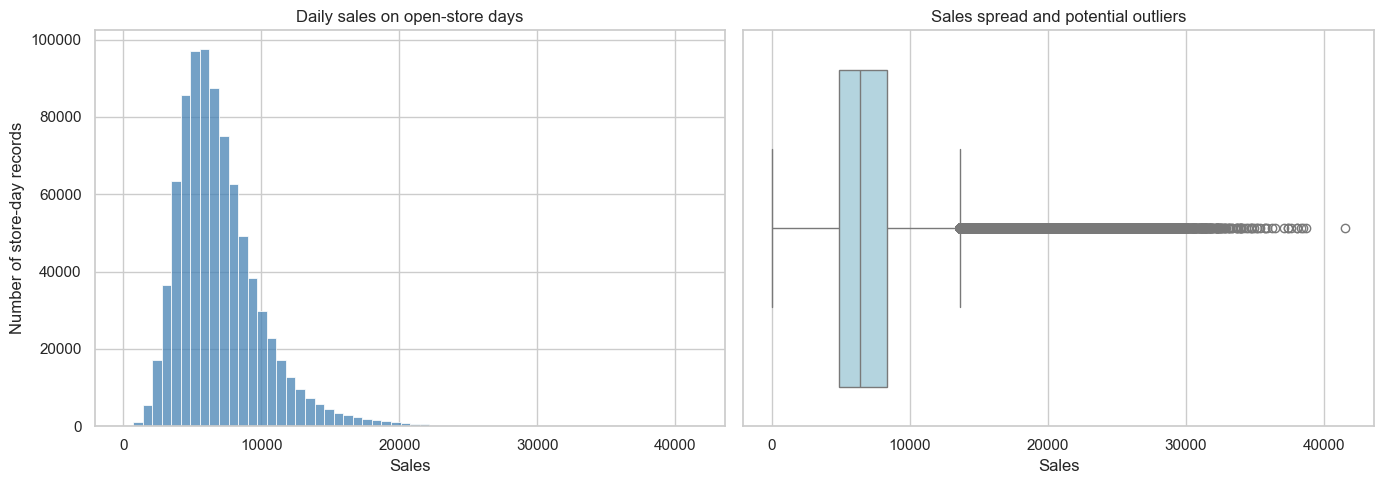

In [13]:
# Analyse open days, including the 54 zero-sales records
open_days = train_merged.loc[train_merged["Open"].eq(1)].copy()

# Folder for saved charts
figures_dir = project_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=open_days,
    x="Sales",
    bins=60,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Daily sales on open-store days")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Number of store-day records")

sns.boxplot(
    data=open_days,
    x="Sales",
    color="lightblue",
    ax=axes[1]
)
axes[1].set_title("Sales spread and potential outliers")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.savefig(
    figures_dir / "01_sales_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

logger.info(
    "Retained 54 zero-sales open records: cause unconfirmed."
)
logger.info(
    "Saved sales distribution charts using %d open-store records.",
    len(open_days)
)

,Train,Test
No promotion,61.85,60.42
Promotion,38.15,39.58


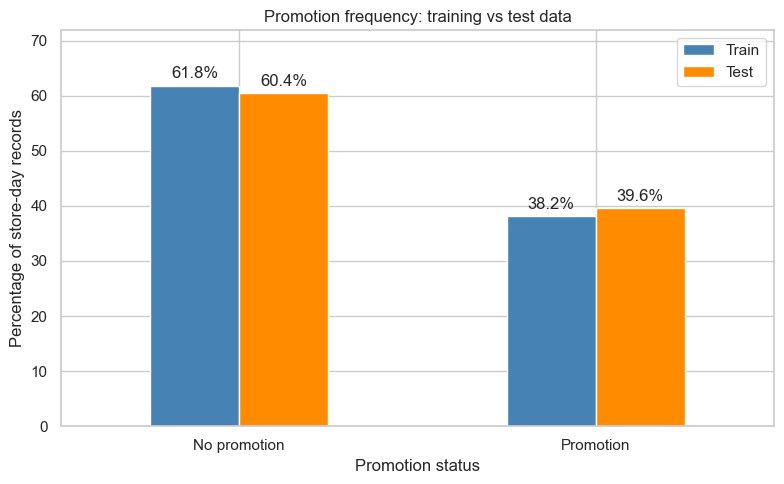

Test minus train promotion share: 1.43 percentage points


In [14]:
# Percentage of store-day records with and without promotions
promo_distribution = pd.DataFrame({
    "Train": train_merged["Promo"].value_counts(normalize=True),
    "Test": test_merged["Promo"].value_counts(normalize=True)
}).reindex([0, 1]).fillna(0) * 100

promo_distribution.index = ["No promotion", "Promotion"]

display(promo_distribution.round(2))

# Compare the percentages visually
ax = promo_distribution.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "darkorange"],
    rot=0
)

ax.set_title("Promotion frequency: training vs test data")
ax.set_xlabel("Promotion status")
ax.set_ylabel("Percentage of store-day records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_ylim(0, promo_distribution.to_numpy().max() + 10)

plt.tight_layout()
plt.savefig(
    figures_dir / "02_promotion_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Difference in promotion frequency
promo_gap = (
    promo_distribution.loc["Promotion", "Test"]
    - promo_distribution.loc["Promotion", "Train"]
)

print(f"Test minus train promotion share: {promo_gap:.2f} percentage points")

logger.info(
    "Compared promotion distributions; test minus train gap = %.2f "
    "percentage points.",
    promo_gap
)

,Store_days,Mean_sales,Median_sales,Mean_customers,Sales_per_customer
Promo,,,,,
0,467496,5929.41,5459.0,696.86,8.51
1,376896,8228.28,7649.0,844.43,9.74


Mean_sales: +38.77% on promotion days
Mean_customers: +21.18% on promotion days
Sales_per_customer: +14.52% on promotion days


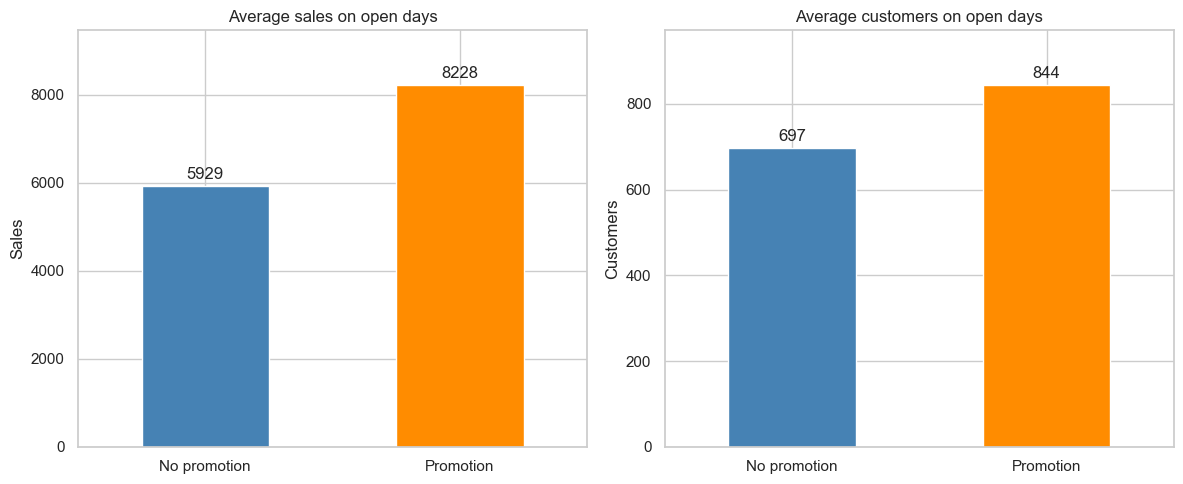

In [15]:
# Summarise open-store days by promotion status
promo_summary = open_days.groupby("Promo").agg(
    Store_days=("Sales", "size"),
    Mean_sales=("Sales", "mean"),
    Median_sales=("Sales", "median"),
    Mean_customers=("Customers", "mean"),
    Total_sales=("Sales", "sum"),
    Total_customers=("Customers", "sum")
)

# Overall sales per recorded customer in each group
promo_summary["Sales_per_customer"] = (
    promo_summary["Total_sales"]
    / promo_summary["Total_customers"]
)

display(
    promo_summary[
        ["Store_days", "Mean_sales", "Median_sales",
         "Mean_customers", "Sales_per_customer"]
    ].round(2)
)

# Percentage differences relative to non-promotion days
for metric in ["Mean_sales", "Mean_customers", "Sales_per_customer"]:
    difference = (
        promo_summary.loc[1, metric]
        / promo_summary.loc[0, metric] - 1
    ) * 100

    print(f"{metric}: {difference:+.2f}% on promotion days")

# Plot sales and customers separately
plot_data = promo_summary.rename(
    index={0: "No promotion", 1: "Promotion"}
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, title, ylabel in [
    (axes[0], "Mean_sales", "Average sales on open days", "Sales"),
    (axes[1], "Mean_customers", "Average customers on open days", "Customers")
]:
    plot_data[metric].plot.bar(
        ax=ax, color=["steelblue", "darkorange"], rot=0
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, plot_data[metric].max() * 1.15)
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig(
    figures_dir / "03_promotion_sales_customers.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

logger.info("Compared sales and customers by Promo on open-store days.")

Sales–customers Pearson correlation: 0.824


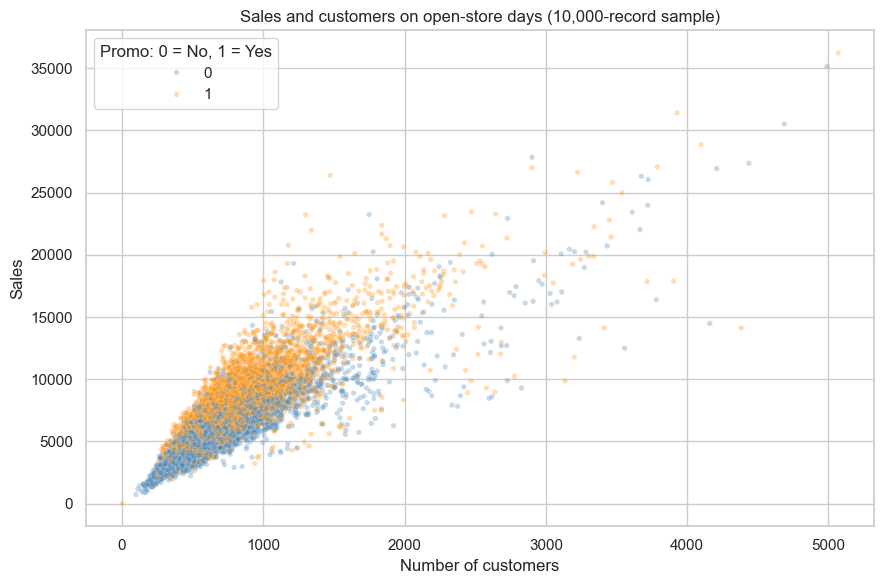

In [16]:
# Calculate correlation using ALL open-store records
correlation = open_days["Sales"].corr(open_days["Customers"])

print(f"Sales–customers Pearson correlation: {correlation:.3f}")

# Use a reproducible sample to keep the chart readable
plot_sample = open_days.sample(
    n=min(10000, len(open_days)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_sample,
    x="Customers",
    y="Sales",
    hue="Promo",
    palette={0: "steelblue", 1: "darkorange"},
    alpha=0.3,
    s=15
)

plt.title("Sales and customers on open-store days (10,000-record sample)")
plt.xlabel("Number of customers")
plt.ylabel("Sales")
plt.legend(title="Promo: 0 = No, 1 = Yes")

plt.tight_layout()
plt.savefig(
    figures_dir / "04_sales_customers_relationship.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

logger.info(
    "Sales–customers Pearson correlation on all open days: %.4f",
    correlation
)

,Recorded_days,Open_rate_pct,Mean_sales_all_days,Mean_sales_open_days,Mean_customers_open_days
DayOfWeek,,,,,
Monday,144730,95.05,7809.04,8216.07,855.44
Tuesday,145664,98.83,7005.24,7088.11,769.99
Wednesday,145665,97.44,6555.88,6728.12,740.60
Thursday,145845,92.32,6247.58,6767.31,755.57
Friday,145845,95.06,6723.27,7072.68,781.77
Saturday,144730,99.54,5847.56,5874.84,660.18
Sunday,144730,2.48,204.18,8224.72,1441.53


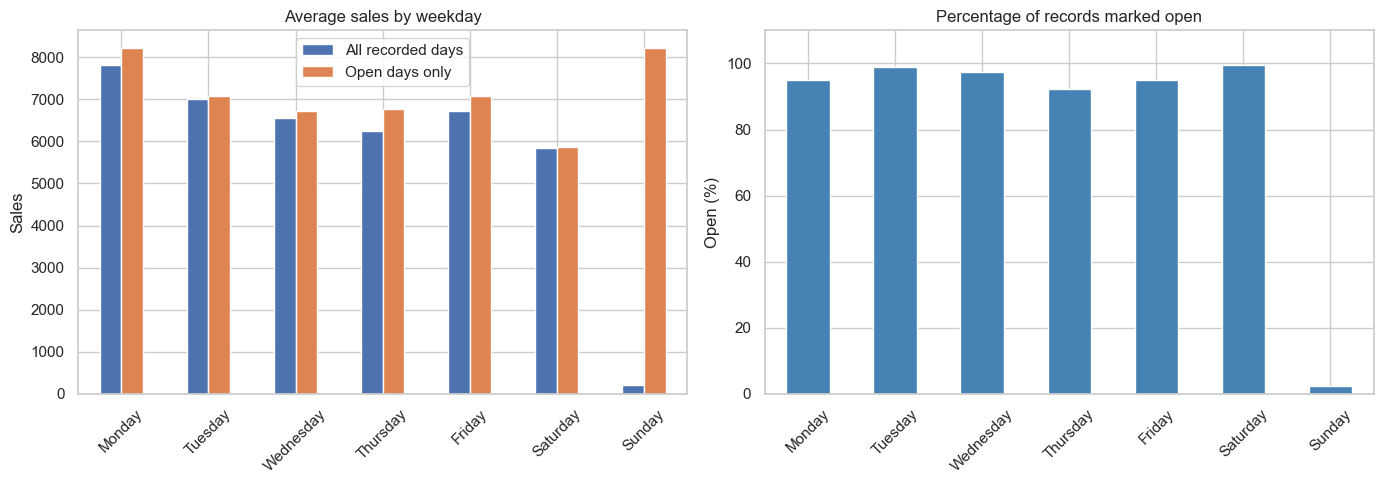

In [17]:
day_names = {
    1: "Monday", 2: "Tuesday", 3: "Wednesday",
    4: "Thursday", 5: "Friday", 6: "Saturday", 7: "Sunday"
}

# Include both open and closed records
weekday_summary = train_merged.groupby("DayOfWeek").agg(
    Recorded_days=("Sales", "size"),
    Open_rate=("Open", "mean"),
    Mean_sales_all_days=("Sales", "mean")
)

# Calculate averages for open-store records separately
open_summary = open_days.groupby("DayOfWeek").agg(
    Mean_sales_open_days=("Sales", "mean"),
    Mean_customers_open_days=("Customers", "mean")
)

weekday_summary = weekday_summary.join(open_summary).reindex(range(1, 8))
weekday_summary["Open_rate_pct"] = weekday_summary["Open_rate"] * 100
weekday_summary = weekday_summary.rename(index=day_names)

display(
    weekday_summary[
        ["Recorded_days", "Open_rate_pct", "Mean_sales_all_days",
         "Mean_sales_open_days", "Mean_customers_open_days"]
    ].round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weekday_summary[
    ["Mean_sales_all_days", "Mean_sales_open_days"]
].rename(columns={
    "Mean_sales_all_days": "All recorded days",
    "Mean_sales_open_days": "Open days only"
}).plot.bar(ax=axes[0], rot=45)

axes[0].set_title("Average sales by weekday")
axes[0].set_xlabel("")
axes[0].set_ylabel("Sales")

weekday_summary["Open_rate_pct"].plot.bar(
    ax=axes[1], color="steelblue", rot=45
)
axes[1].set_title("Percentage of records marked open")
axes[1].set_xlabel("")
axes[1].set_ylabel("Open (%)")
axes[1].set_ylim(0, 110)

plt.tight_layout()
plt.savefig(
    figures_dir / "05_weekday_sales_opening.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

logger.info("Compared weekday sales, customers, and opening rates.")

In [18]:
# Check each store's Monday–Friday opening history
weekday_records = train_merged.loc[
    train_merged["DayOfWeek"].between(1, 5)
]

store_weekday_status = weekday_records.groupby("Store").agg(
    Weekday_records=("Open", "size"),
    Weekday_types=("DayOfWeek", "nunique"),
    Minimum_open=("Open", "min")
)

always_open_ids = store_weekday_status.index[
    store_weekday_status["Minimum_open"].eq(1)
    & store_weekday_status["Weekday_types"].eq(5)
]

print("Stores open on every recorded weekday:", len(always_open_ids))
print("Store IDs:", always_open_ids.tolist())

# Compare weekend records for these stores and other stores
weekend_records = train_merged.loc[
    train_merged["DayOfWeek"].isin([6, 7])
].copy()

weekend_records["Store_group"] = np.where(
    weekend_records["Store"].isin(always_open_ids),
    "Always open on recorded weekdays",
    "Other stores"
)

weekend_records["Weekend_day"] = (
    weekend_records["DayOfWeek"].map({6: "Saturday", 7: "Sunday"})
)

weekend_summary = weekend_records.groupby(
    ["Store_group", "Weekend_day"]
).agg(
    Records=("Sales", "size"),
    Stores=("Store", "nunique"),
    Open_rate=("Open", "mean"),
    Mean_sales_all_days=("Sales", "mean")
)

weekend_open_sales = (
    weekend_records.loc[weekend_records["Open"].eq(1)]
    .groupby(["Store_group", "Weekend_day"])["Sales"]
    .mean()
    .rename("Mean_sales_open_days")
)

weekend_summary = weekend_summary.join(weekend_open_sales)
weekend_summary["Open_rate_pct"] = weekend_summary.pop("Open_rate") * 100

display(weekend_summary.round(2))

logger.info(
    "Found %d stores open on every recorded Monday–Friday; "
    "compared weekend sales by store group.",
    len(always_open_ids)
)

Stores open on every recorded weekday: 10
Store IDs: [85, 262, 335, 423, 494, 562, 682, 733, 769, 1097]


Records  Stores  \
Store_group                      Weekend_day                    
Always open on recorded weekdays Saturday        1340      10   
                                 Sunday          1340      10   
Other stores                     Saturday      143390    1105   
                                 Sunday        143390    1105   

                                              Mean_sales_all_days  \
Store_group                      Weekend_day                        
Always open on recorded weekdays Saturday                10004.73   
                                 Sunday                  13249.49   
Other stores                     Saturday                 5808.71   
                                 Sunday                     82.27   

                                              Mean_sales_open_days  \
Store_group                      Weekend_day                         
Always open on recorded weekdays Saturday                 10004.73   
                                 Sunday                   13249.49   
Other stores                     Saturday                  5836.06   
                                 Sunday                    5236.18   

                                              Open_rate_pct  
Store_group                      Weekend_day                 
Always open on recorded weekdays Saturday            100.00  
                                 Sunday              100.00  
Other stores                     Saturday             99.53  
                                 Sunday                1.57

,Stores,Store_days,Mean_sales,Median_sales,Mean_customers,Sales_per_customer
Assortment,,,,,,
a,593,444909,6621.02,6082.0,747.94,8.85
b,9,8212,8639.35,8081.0,2066.80,4.18
c,513,391271,7300.53,6675.0,752.17,9.71


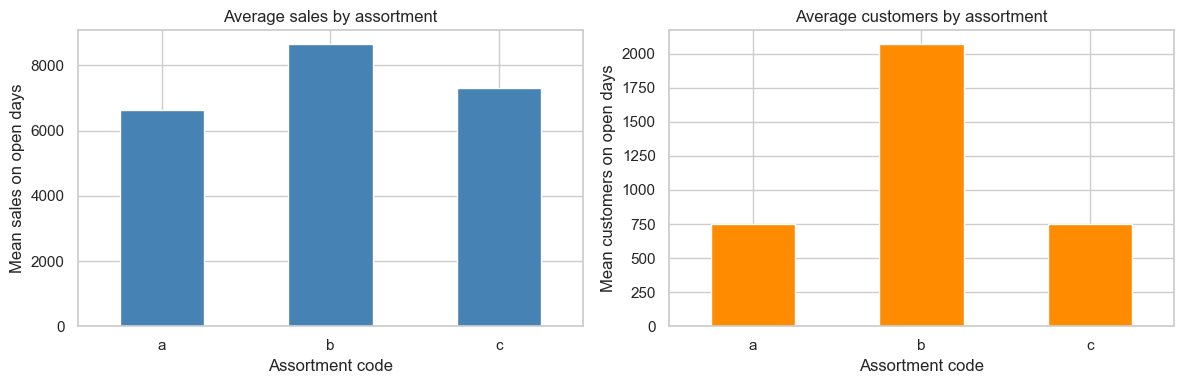

In [19]:
assortment_summary = (
    open_days.groupby("Assortment")
    .agg(
        Stores=("Store", "nunique"),
        Store_days=("Sales", "size"),
        Mean_sales=("Sales", "mean"),
        Median_sales=("Sales", "median"),
        Mean_customers=("Customers", "mean"),
        Total_sales=("Sales", "sum"),
        Total_customers=("Customers", "sum"),
    )
)

assortment_summary["Sales_per_customer"] = (
    assortment_summary["Total_sales"]
    / assortment_summary["Total_customers"]
)

display(
    assortment_summary[
        [
            "Stores", "Store_days", "Mean_sales",
            "Median_sales", "Mean_customers", "Sales_per_customer"
        ]
    ].round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

assortment_summary["Mean_sales"].plot.bar(
    ax=axes[0], color="steelblue", rot=0
)
axes[0].set_title("Average sales by assortment")
axes[0].set_ylabel("Mean sales on open days")
axes[0].set_xlabel("Assortment code")

assortment_summary["Mean_customers"].plot.bar(
    ax=axes[1], color="darkorange", rot=0
)
axes[1].set_title("Average customers by assortment")
axes[1].set_ylabel("Mean customers on open days")
axes[1].set_xlabel("Assortment code")

plt.tight_layout()
fig.savefig(
    figures_dir / "06_assortment_sales_customers.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

logger.info("Compared open-day sales and customers by assortment.")

,Stores,Open_store_days,Mean_sales,Mean_customers,Promo_share_pct
Month,,,,,
2013-01,1112,28869,6239.64,705.96,38.32
2013-02,1112,26683,6428.60,721.23,41.60
2013-03,1112,27892,7212.83,787.66,55.78
2013-04,1113,27880,6579.32,749.01,47.74
2013-05,1113,26202,7076.22,790.93,48.38
2013-06,1113,27942,6467.05,732.70,39.78
2013-07,1115,30166,6923.15,758.21,47.93
2013-08,1115,30025,6595.93,743.19,43.99
2013-09,1115,27981,6363.39,727.28,39.78


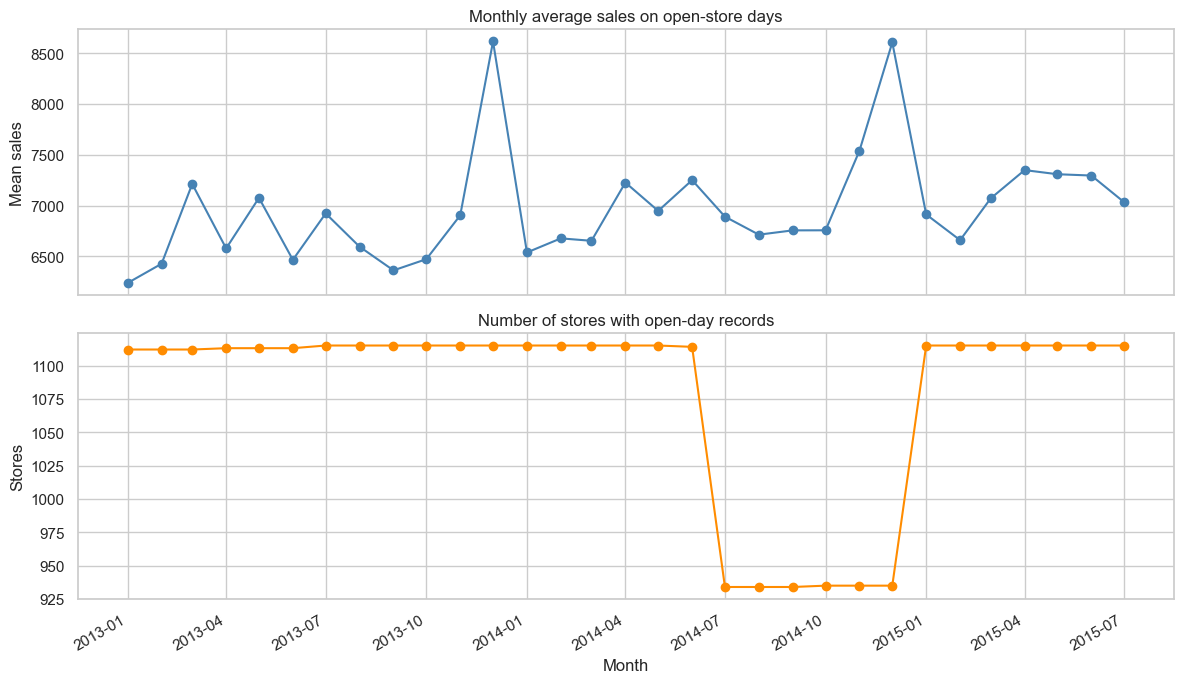

In [20]:
monthly_data = open_days.assign(
    Month=open_days["Date"].dt.to_period("M")
)

monthly_summary = (
    monthly_data.groupby("Month")
    .agg(
        Stores=("Store", "nunique"),
        Open_store_days=("Sales", "size"),
        Mean_sales=("Sales", "mean"),
        Mean_customers=("Customers", "mean"),
        Promo_share=("Promo", "mean"),
    )
)

monthly_summary["Promo_share_pct"] = (
    monthly_summary.pop("Promo_share") * 100
)

display(monthly_summary.round(2))

month_dates = monthly_summary.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    month_dates,
    monthly_summary["Mean_sales"],
    marker="o",
    color="steelblue",
)
axes[0].set_title("Monthly average sales on open-store days")
axes[0].set_ylabel("Mean sales")

axes[1].plot(
    month_dates,
    monthly_summary["Stores"],
    marker="o",
    color="darkorange",
)
axes[1].set_title("Number of stores with open-day records")
axes[1].set_ylabel("Stores")
axes[1].set_xlabel("Month")

fig.autofmt_xdate()
plt.tight_layout()
fig.savefig(
    figures_dir / "07_monthly_sales_patterns.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

logger.info("Summarised monthly sales, customers, and store coverage.")

In [21]:
coverage_data = train_merged.assign(
    Month=train_merged["Date"].dt.to_period("M")
)

monthly_coverage = coverage_data.groupby("Month").agg(
    Stores_with_records=("Store", "nunique"),
    Recorded_store_days=("Store", "size"),
    Dates_present=("Date", "nunique"),
)

monthly_coverage["Stores_with_open_days"] = (
    monthly_summary["Stores"]
)

monthly_coverage["Stores_without_records"] = (
    store_clean["Store"].nunique()
    - monthly_coverage["Stores_with_records"]
)

monthly_coverage["Stores_recorded_but_never_open"] = (
    monthly_coverage["Stores_with_records"]
    - monthly_coverage["Stores_with_open_days"]
)

display(
    monthly_coverage.loc["2014-06":"2015-01"]
)

# Find stores with at least one recorded row in every observed month.
months_per_store = coverage_data.groupby("Store")["Month"].nunique()
total_months = coverage_data["Month"].nunique()

consistent_store_ids = months_per_store.index[
    months_per_store.eq(total_months)
]

print(
    "Stores with records in every observed month:",
    len(consistent_store_ids),
)

logger.info(
    "Checked monthly record coverage; %d stores have records "
    "in every observed month.",
    len(consistent_store_ids),
)

,Stores_with_records,Recorded_store_days,Dates_present,Stores_with_open_days,Stores_without_records,Stores_recorded_but_never_open
Month,,,,,,
2014-06,1115,33450,30,1114,0,1
2014-07,935,28985,31,934,180,1
2014-08,935,28985,31,934,180,1
2014-09,935,28050,30,934,180,1
2014-10,935,28985,31,935,180,0
2014-11,935,28050,30,935,180,0
2014-12,935,28985,31,935,180,0
2015-01,1115,34565,31,1115,0,0


Stores with records in every observed month: 935


,Mean_sales,Stores_with_open_days
Month,,
2013-01,6279.20,932
2013-02,6503.83,932
2013-03,7285.38,932
2013-04,6643.50,933
2013-05,7112.95,933
2013-06,6510.26,933
2013-07,6966.58,935
2013-08,6621.32,935
2013-09,6399.21,935


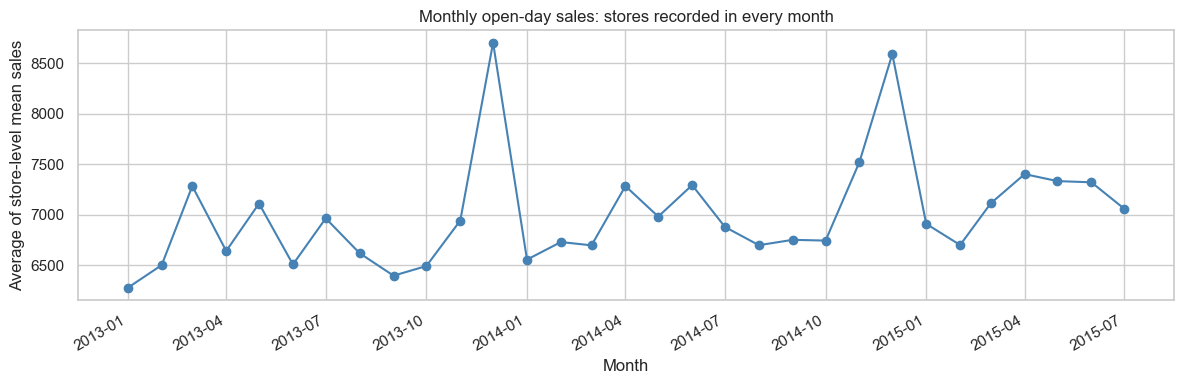

In [22]:
consistent_open_days = open_days.loc[
    open_days["Store"].isin(consistent_store_ids)
].copy()

consistent_open_days["Month"] = (
    consistent_open_days["Date"].dt.to_period("M")
)

# Average within each store first, then give each store equal weight.
store_month_sales = (
    consistent_open_days.groupby(["Store", "Month"])["Sales"]
    .mean()
    .rename("Mean_sales")
    .reset_index()
)

consistent_monthly = store_month_sales.groupby("Month").agg(
    Mean_sales=("Mean_sales", "mean"),
    Stores_with_open_days=("Store", "nunique"),
)

display(consistent_monthly.round(2))

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    consistent_monthly.index.to_timestamp(),
    consistent_monthly["Mean_sales"],
    marker="o",
    color="steelblue",
)

ax.set_title("Monthly open-day sales: stores recorded in every month")
ax.set_xlabel("Month")
ax.set_ylabel("Average of store-level mean sales")

fig.autofmt_xdate()
plt.tight_layout()
fig.savefig(
    figures_dir / "08_consistent_store_monthly_sales.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

logger.info(
    "Compared monthly open-day sales for %d consistently recorded "
    "stores, weighting each store equally.",
    len(consistent_store_ids),
)

,Store_days,Stores,Mean_sales_all_days,Open_store_days,Mean_sales_open_days,Mean_customers_open_days,Open_rate_pct
Holiday_type,,,,,,,
No state holiday,986159,1115,5947.48,843482,6953.52,762.08,85.53
Public holiday,20260,1115,290.74,694,8487.47,1279.17,3.43
Easter,6690,1115,214.31,145,9887.89,1686.89,2.17
Christmas,4100,1115,168.73,71,9743.75,1569.23,1.73


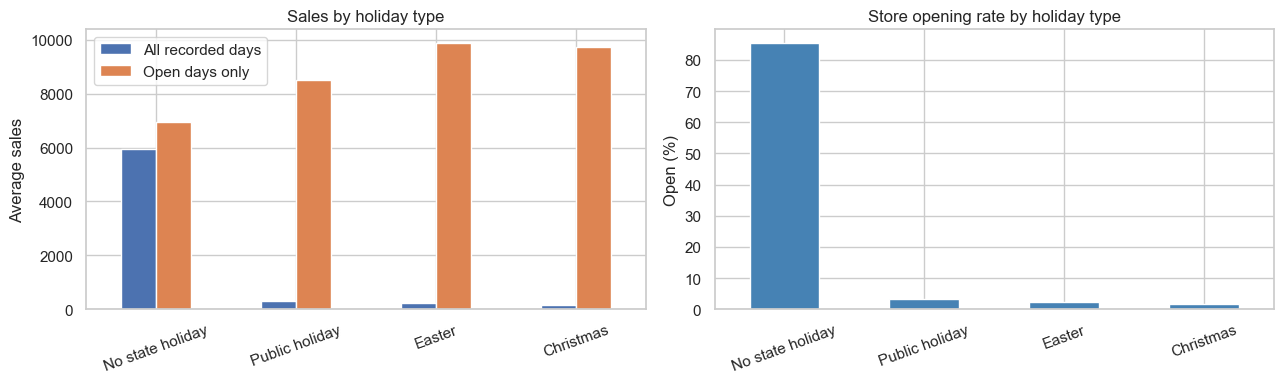

In [23]:
holiday_names = {
    "0": "No state holiday",
    "a": "Public holiday",
    "b": "Easter",
    "c": "Christmas",
}

holiday_data = train_merged.copy()
holiday_data["Holiday_type"] = (
    holiday_data["StateHoliday"].astype("string").map(holiday_names)
)

holiday_summary = holiday_data.groupby("Holiday_type").agg(
    Store_days=("Sales", "size"),
    Stores=("Store", "nunique"),
    Open_rate=("Open", "mean"),
    Mean_sales_all_days=("Sales", "mean"),
)

holiday_open_summary = (
    holiday_data.loc[holiday_data["Open"].eq(1)]
    .groupby("Holiday_type")
    .agg(
        Open_store_days=("Sales", "size"),
        Mean_sales_open_days=("Sales", "mean"),
        Mean_customers_open_days=("Customers", "mean"),
    )
)

holiday_summary = holiday_summary.join(holiday_open_summary)
holiday_summary["Open_rate_pct"] = (
    holiday_summary.pop("Open_rate") * 100
)

holiday_summary = holiday_summary.reindex(holiday_names.values())
display(holiday_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

holiday_summary[
    ["Mean_sales_all_days", "Mean_sales_open_days"]
].rename(columns={
    "Mean_sales_all_days": "All recorded days",
    "Mean_sales_open_days": "Open days only",
}).plot.bar(ax=axes[0], rot=20)

axes[0].set_title("Sales by holiday type")
axes[0].set_ylabel("Average sales")
axes[0].set_xlabel("")

holiday_summary["Open_rate_pct"].plot.bar(
    ax=axes[1], color="steelblue", rot=20
)
axes[1].set_title("Store opening rate by holiday type")
axes[1].set_ylabel("Open (%)")
axes[1].set_xlabel("")

plt.tight_layout()
fig.savefig(
    figures_dir / "09_holiday_sales_opening.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

logger.info("Compared sales and opening rates by state holiday type.")

In [24]:
# Identify each store's Easter and Christmas periods by year.
event_rows = train_merged.loc[
    train_merged["StateHoliday"].isin(["b", "c"]),
    ["Store", "Date", "StateHoliday"]
].copy()

event_rows["Year"] = event_rows["Date"].dt.year

holiday_events = (
    event_rows.groupby(["Store", "Year", "StateHoliday"])["Date"]
    .agg(Start="min", End="max")
    .reset_index()
)

# Build calendar windows, then match actual recorded store-days.
windows = []

for event in holiday_events.itertuples(index=False):
    dates = pd.date_range(
        event.Start - pd.Timedelta(days=7),
        event.End + pd.Timedelta(days=7),
    )

    windows.append(pd.DataFrame({
        "Store": event.Store,
        "Date": dates,
        "Holiday": holiday_names[event.StateHoliday],
        "Period": np.where(
            dates < event.Start, "Before",
            np.where(dates > event.End, "After", "During")
        ),
    }))

holiday_windows = pd.concat(windows, ignore_index=True)

holiday_comparison = holiday_windows.merge(
    train_merged[["Store", "Date", "Sales", "Customers", "Open"]],
    on=["Store", "Date"],
    how="left",
    validate="many_to_one",
)

print("Window days without records:",
      holiday_comparison["Open"].isna().sum())

# Missing records remain missing; they are not treated as zero sales.
recorded_windows = holiday_comparison.dropna(subset=["Open"]).copy()
recorded_windows["Open_day_sales"] = recorded_windows["Sales"].where(
    recorded_windows["Open"].eq(1)
)

window_summary = recorded_windows.groupby(["Holiday", "Period"]).agg(
    Recorded_store_days=("Sales", "size"),
    Open_store_days=("Open", "sum"),
    Open_rate=("Open", "mean"),
    Mean_sales_all_days=("Sales", "mean"),
    Mean_sales_open_days=("Open_day_sales", "mean"),
)

window_summary["Open_rate_pct"] = window_summary.pop("Open_rate") * 100

display(window_summary.reindex(
    pd.MultiIndex.from_product(
        [["Easter", "Christmas"], ["Before", "During", "After"]],
        names=["Holiday", "Period"],
    )
).round(2))

logger.info("Compared seven-day windows around Easter and Christmas.")

Window days without records: 0


Recorded_store_days  Open_store_days  Mean_sales_all_days  \
Holiday   Period                                                              
Easter    Before                23415            20133              7352.53   
          During                13380             3580              2181.55   
          After                 23415            20119              5600.21   
Christmas Before                14350            12355              8372.93   
          During                 4100               71               168.73   
          After                 14350            10333              4758.30   

                  Mean_sales_open_days  Open_rate_pct  
Holiday   Period                                       
Easter    Before               8551.11          85.98  
          During               8153.39          26.76  
          After                6517.67          85.92  
Christmas Before               9724.93          86.10  
          During               9743.75           1.73  
          After                6608.11          72.01

,Stores,Mean_store_sales,Median_store_sales,Mean_store_customers
Distance_group,,,,
0–500 m,220,7581.49,7016.61,960.33
"501–2,000 m",282,6873.24,6216.97,795.37
"2,001–5,000 m",261,6675.97,6464.92,688.46
"Over 5,000 m",349,6782.03,6629.75,643.00
Unknown,3,5368.00,4317.96,539.23


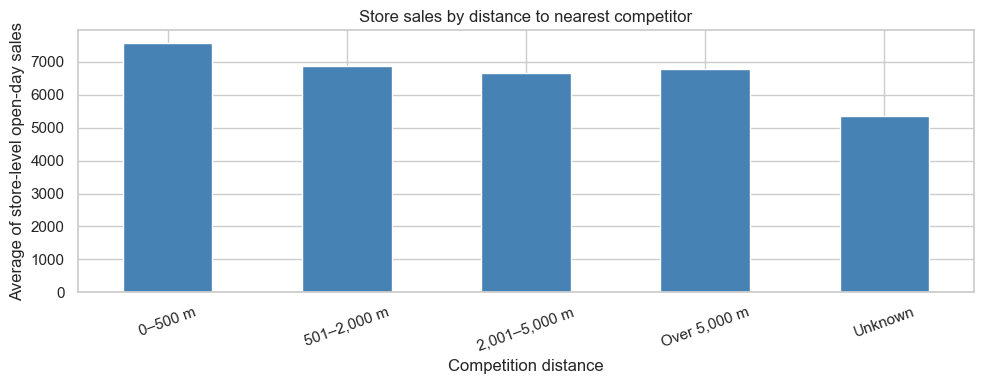

In [25]:
store_sales = open_days.groupby("Store").agg(
    Mean_sales=("Sales", "mean"),
    Mean_customers=("Customers", "mean"),
    Open_days=("Sales", "size"),
)

competition_analysis = store_sales.join(
    store_clean.set_index("Store")[["CompetitionDistance"]],
    validate="one_to_one",
)

distance_labels = [
    "0–500 m",
    "501–2,000 m",
    "2,001–5,000 m",
    "Over 5,000 m",
]

competition_analysis["Distance_group"] = pd.cut(
    competition_analysis["CompetitionDistance"],
    bins=[0, 500, 2000, 5000, np.inf],
    labels=distance_labels,
    include_lowest=True,
)

competition_analysis["Distance_group"] = (
    competition_analysis["Distance_group"]
    .cat.add_categories(["Unknown"])
    .fillna("Unknown")
)

competition_summary = (
    competition_analysis.groupby("Distance_group", observed=True)
    .agg(
        Stores=("Mean_sales", "size"),
        Mean_store_sales=("Mean_sales", "mean"),
        Median_store_sales=("Mean_sales", "median"),
        Mean_store_customers=("Mean_customers", "mean"),
    )
)

display(competition_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 4))

competition_summary["Mean_store_sales"].plot.bar(
    ax=ax, color="steelblue", rot=20
)

ax.set_title("Store sales by distance to nearest competitor")
ax.set_xlabel("Competition distance")
ax.set_ylabel("Average of store-level open-day sales")

plt.tight_layout()
fig.savefig(
    figures_dir / "10_competition_distance_sales.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

logger.info("Compared store-level sales by competition distance.")

In [26]:
competition_timing = open_days[
    ["Store", "Date", "Sales",
     "CompetitionOpenSinceYear", "CompetitionOpenSinceMonth"]
].dropna(
    subset=["CompetitionOpenSinceYear", "CompetitionOpenSinceMonth"]
).copy()

competition_timing["Month_offset"] = (
    competition_timing["Date"].dt.year * 12
    + competition_timing["Date"].dt.month
    - (
        competition_timing["CompetitionOpenSinceYear"] * 12
        + competition_timing["CompetitionOpenSinceMonth"]
    )
).astype(int)

comparison_months = [-3, -2, -1, 1, 2, 3]

competition_timing = competition_timing.loc[
    competition_timing["Month_offset"].isin(comparison_months)
]

# Calculate each store's average sales in each comparison month.
opening_monthly = (
    competition_timing.groupby(["Store", "Month_offset"])["Sales"]
    .mean()
    .unstack("Month_offset")
    .reindex(columns=comparison_months)
)

eligible_openings = opening_monthly.dropna().copy()

opening_comparison = pd.DataFrame({
    "Before": eligible_openings[[-3, -2, -1]].mean(axis=1),
    "After": eligible_openings[[1, 2, 3]].mean(axis=1),
})

opening_comparison["Change_pct"] = (
    (
        opening_comparison["After"]
        / opening_comparison["Before"].replace(0, np.nan)
    ) - 1
) * 100

print("Stores with open-day data in all six months:",
      len(opening_comparison))

display(opening_comparison.head(10).round(2))

display(
    opening_comparison.agg(["mean", "median"]).round(2)
)

logger.info(
    "Compared sales around competitor openings for %d stores "
    "with open-day data in all six comparison months.",
    len(opening_comparison),
)

Stores with open-day data in all six months: 145


,Before,After,Change_pct
Store,,,
5,4545.44,4691.54,3.21
6,6365.87,4918.61,-22.73
7,7735.51,9163.94,18.47
8,5346.22,6488.26,21.36
14,5758.57,5773.51,0.26
28,6113.50,4849.23,-20.68
30,6124.74,5014.23,-18.13
33,9157.23,8072.47,-11.85
37,6897.61,6633.49,-3.83


,Before,After,Change_pct
mean,7506.28,7100.54,-4.48
median,6993.58,6488.26,-3.22


In [27]:
# Compare ordinary open weekdays where both promo states occur.
promo_records = open_days.loc[
    open_days["DayOfWeek"].between(1, 5)
    & open_days["StateHoliday"].eq("0")
].copy()

promo_groups = (
    promo_records.groupby(["Store", "DayOfWeek", "Promo"])
    .agg(
        Mean_sales=("Sales", "mean"),
        Days=("Sales", "size"),
    )
)

promo_means = promo_groups["Mean_sales"].unstack("Promo").reindex(
    columns=[0, 1]
)
promo_counts = promo_groups["Days"].unstack("Promo").reindex(
    columns=[0, 1]
)

# Require at least 20 observations in each promotion group.
eligible = promo_counts.ge(20).all(axis=1)
weekday_comparison = promo_means.loc[eligible].dropna().copy()

weekday_comparison.columns = ["No_promo", "Promo"]
weekday_comparison["Difference"] = (
    weekday_comparison["Promo"] - weekday_comparison["No_promo"]
)

store_promo_comparison = weekday_comparison.groupby("Store").agg(
    Weekdays_compared=("Difference", "size"),
    Mean_no_promo_sales=("No_promo", "mean"),
    Mean_promo_sales=("Promo", "mean"),
    Mean_sales_difference=("Difference", "mean"),
)

# Keep stores with comparisons available for all five weekdays.
store_promo_comparison = store_promo_comparison.loc[
    store_promo_comparison["Weekdays_compared"].eq(5)
].copy()

store_promo_comparison["Difference_pct"] = (
    store_promo_comparison["Mean_sales_difference"]
    / store_promo_comparison["Mean_no_promo_sales"].replace(0, np.nan)
) * 100

print("Stores meeting comparison requirements:",
      len(store_promo_comparison))

print("\nTop 10 stores by absolute sales difference:")
display(
    store_promo_comparison.sort_values(
        "Mean_sales_difference", ascending=False
    ).head(10).round(2)
)

print("\nDistribution of percentage differences:")
display(
    store_promo_comparison["Difference_pct"].describe().round(2)
)

logger.info(
    "Compared promotion sales within store and weekday for %d stores.",
    len(store_promo_comparison),
)

Stores meeting comparison requirements: 1115

Top 10 stores by absolute sales difference:


,Weekdays_compared,Mean_no_promo_sales,Mean_promo_sales,Mean_sales_difference,Difference_pct
Store,,,,,
261,5,9745.66,16897.01,7151.35,73.38
335,5,12186.94,18369.96,6183.02,50.73
1027,5,10347.46,16132.02,5784.56,55.90
544,5,12045.89,17409.29,5363.40,44.52
380,5,11654.08,17017.01,5362.93,46.02
234,5,8431.20,13751.39,5320.18,63.10
368,5,7053.42,12300.95,5247.53,74.40
831,5,10613.65,15656.12,5042.47,47.51
1112,5,7863.73,12804.73,4941.00,62.83



Distribution of percentage differences:


count    1115.00
mean       39.67
std        12.57
min         1.94
25%        31.04
50%        39.10
75%        47.32
max       101.83
Name: Difference_pct, dtype: float64

In [28]:
outlier_review = open_days[
    ["Store", "Date", "Sales", "Promo", "DayOfWeek"]
].copy()

sales_groups = outlier_review.groupby(["Store", "Promo"])["Sales"]

q1 = sales_groups.transform("quantile", q=0.25)
q3 = sales_groups.transform("quantile", q=0.75)
iqr = q3 - q1

outlier_review["Lower_bound"] = q1 - 1.5 * iqr
outlier_review["Upper_bound"] = q3 + 1.5 * iqr

outlier_review["Potential_outlier"] = (
    outlier_review["Sales"].lt(outlier_review["Lower_bound"])
    | outlier_review["Sales"].gt(outlier_review["Upper_bound"])
)

flagged = outlier_review.loc[
    outlier_review["Potential_outlier"]
].copy()

print(f"Open-store records reviewed: {len(outlier_review):,}")
print(f"Potential outliers: {len(flagged):,}")
print(
    f"Percentage flagged: "
    f"{outlier_review['Potential_outlier'].mean() * 100:.2f}%"
)

print("\nHighest-sales flagged records:")
display(
    flagged.sort_values("Sales", ascending=False)
    .head(10)
    .round(2)
)

print("\nPercentage flagged within each calendar month:")
monthly_outlier_rate = (
    outlier_review.assign(
        Month=outlier_review["Date"].dt.month
    )
    .groupby("Month")["Potential_outlier"]
    .mean()
    .mul(100)
    .rename("Flagged_pct")
)

display(monthly_outlier_rate.round(2))

logger.info(
    "Flagged %d of %d open-day records using within-store, "
    "within-promotion IQR bounds; no records removed.",
    len(flagged),
    len(outlier_review),
)

Open-store records reviewed: 844,392
Potential outliers: 22,369
Percentage flagged: 2.65%

Highest-sales flagged records:


C:\Users\mahim\AppData\Local\Temp\ipykernel_14568\1938135371.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,Store,Date,Sales,Promo,DayOfWeek,Lower_bound,Upper_bound,Potential_outlier
44393,909,2015-06-22,41551,0,1,5807.38,11270.38,True
132946,262,2015-04-03,38722,1,5,15028.75,25842.75,True
101726,262,2015-05-01,38484,1,5,15028.75,25842.75,True
87231,262,2015-05-14,38367,0,4,6983.00,32943.00,True
424086,57,2014-06-16,38037,1,1,4935.38,20378.38,True
627776,817,2013-12-16,38025,1,1,16067.50,33751.50,True
627220,261,2013-12-16,37646,1,1,8057.25,24907.25,True
444361,262,2014-05-29,37403,0,4,6983.00,32943.00,True
620531,262,2013-12-22,37376,0,7,6983.00,32943.00,True
245945,262,2014-12-21,37122,0,7,6983.00,32943.00,True



Percentage flagged within each calendar month:


Month
1      1.03
2      1.28
3      2.16
4      2.00
5      2.81
6      1.52
7      0.63
8      0.87
9      0.67
10     1.28
11     2.45
12    20.12
Name: Flagged_pct, dtype: float64

In [29]:
display(
    flagged.sort_values("Sales", ascending=False)
    .head(10)
    .round({"Lower_bound": 2, "Upper_bound": 2})
)

,Store,Date,Sales,Promo,DayOfWeek,Lower_bound,Upper_bound,Potential_outlier
44393,909,2015-06-22,41551,0,1,5807.38,11270.38,True
132946,262,2015-04-03,38722,1,5,15028.75,25842.75,True
101726,262,2015-05-01,38484,1,5,15028.75,25842.75,True
87231,262,2015-05-14,38367,0,4,6983.00,32943.00,True
424086,57,2014-06-16,38037,1,1,4935.38,20378.38,True
627776,817,2013-12-16,38025,1,1,16067.50,33751.50,True
627220,261,2013-12-16,37646,1,1,8057.25,24907.25,True
444361,262,2014-05-29,37403,0,4,6983.00,32943.00,True
620531,262,2013-12-22,37376,0,7,6983.00,32943.00,True
245945,262,2014-12-21,37122,0,7,6983.00,32943.00,True


In [30]:
tables_dir = project_dir / "reports" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

eda_tables = {
    "promotion_distribution": promo_distribution,
    "promotion_summary": promo_summary,
    "weekday_summary": weekday_summary,
    "weekend_summary": weekend_summary,
    "assortment_summary": assortment_summary,
    "monthly_summary": monthly_summary,
    "monthly_coverage": monthly_coverage,
    "consistent_store_monthly_sales": consistent_monthly,
    "holiday_summary": holiday_summary,
    "holiday_windows": window_summary,
    "competition_distance": competition_summary,
    "competitor_opening_comparison": opening_comparison,
    "store_promotion_comparison": store_promo_comparison,
    "monthly_outlier_rate": monthly_outlier_rate,
}

for name, table in eda_tables.items():
    table.to_csv(tables_dir / f"{name}.csv")

outlier_summary = pd.DataFrame({
    "Records_reviewed": [len(outlier_review)],
    "Records_flagged": [len(flagged)],
    "Flagged_pct": [
        outlier_review["Potential_outlier"].mean() * 100
    ],
    "Records_removed": [0],
})

outlier_summary.to_csv(
    tables_dir / "outlier_summary.csv", index=False
)

logger.info("Saved %d EDA summary tables.", len(eda_tables) + 1)

print(f"Saved {len(eda_tables) + 1} tables.")
print("Location:", tables_dir)

Saved 15 tables.
Location: d:\DigiCrome Academy\Internship\Nexthikes\P6\reports\tables


## EDA findings and modelling decisions

### Data quality
- Training data contains 1,017,209 records across 1,115 stores.
- No duplicate Store–Date pairs were found.
- The 11 missing test Open values belonged to Store 622.
  They were filled with 1 based on historical opening patterns,
  with a missing-value indicator retained.
- Missing Promo2 details corresponded to non-participating stores.
- Missing competition information was retained with indicators.
  Numerical imputation will be fitted within the modelling pipeline.

### Sales and customer patterns
- Sales and customers have a strong positive correlation of 0.824
  on open-store days.
- Actual future customer counts are unavailable in the test data,
  so Customers will not be used directly as a sales-model input.
- Sunday opening is uncommon: only 2.48% of recorded Sunday
  store-days were open. Open-Sunday sales represent a selected
  group of stores.

### Promotions and assortment
- Promotion shares are similar in train and test:
  38.15% and 39.58%, respectively.
- Within-store, same-weekday comparisons show an average
  promotion-associated sales difference of +39.67%.
- Stores 261, 335, and 1027 have the largest absolute differences
  and are candidates for controlled promotion testing.
- Assortment group b has the highest average sales and customer
  count, but includes only 9 stores.
- These observational comparisons do not establish causality
  or promotion profitability.

### Seasonality and holidays
- December sales peaks remain when examining stores recorded
  in every month and weighting contributing stores equally.
- Store coverage falls during July–December 2014.
  Missing records must not be interpreted as zero sales.
- Sales before Easter and Christmas exceed sales in the
  corresponding seven-day periods afterward.
- Holiday closures strongly reduce all-day sales averages.
- The Easter window includes the intervening weekend;
  the post-Christmas window includes New Year's Day.

### Competition
- Stores within 500 metres of a competitor have the highest
  average sales among the distance groups.
- Eligible stores show a mean store-level sales change of
  -4.48% after recorded competitor openings.
- Seasonality, location, and promotions may influence these
  relationships; they are not causal estimates.
- Static store metadata cannot reveal competitor reopening
  histories or changes from unknown to known distance.

### Outlier treatment
- Within-store, within-promotion IQR checks flagged 22,369
  open-day records (2.65%).
- December has a 20.12% flag rate, consistent with seasonal peaks.
- No records were removed solely because of an IQR flag.
- The 54 open-store records with zero sales were retained
  because their cause is unconfirmed.
- Target-derived outlier flags will not be forecasting inputs.

### Next modelling steps
- Use chronological validation to simulate forecasting
  six weeks ahead.
- Fit learned preprocessing only on the training period.
- Compare a simple baseline with machine-learning models.
- Evaluate sales predictions and analyse errors by store,
  promotion status, and forecast horizon.

### Analysis limitations
- Daily totals cannot reveal within-day customer patterns.
- Customer identities are unavailable, so new and returning
  customers cannot be distinguished.
- Store locations are unavailable, so city-centre effects
  cannot be tested directly.
- Full-data EDA has already been performed; subsequent validation
  is a development backtest, not a completely untouched evaluation.